# 02 - Exploratory Data Analysis

**Owner:** Rajneesh  |  **Project:** Customer Churn Prediction

Goals: profile the data, find missing values and duplicates, check class balance, study how each
feature relates to churn (bivariate analysis), and check whether the training and testing files
come from the same distribution. Findings feed the cleaning rules (notebook 03) and the feature
ideas in the Design Document.

In [1]:
import sys, os
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

from src import config, data_utils

sns.set_theme(style="whitegrid")
FIG_DIR = "../docs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()

## 1. Load and profile

In [2]:
train = data_utils.load_raw("train")
test = data_utils.load_raw("test")
print("train:", train.shape, "| test:", test.shape)
train.head()

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


[10/19/26 07:09:59] INFO     Initializing a Ray instance                                               ]8;id=6767285;file:///opt/conda/lib/python3.12/site-packages/awswrangler/distributed/ray/_core.py\_core.py]8;;\:]8;id=6767286;file:///opt/conda/lib/python3.12/site-packages/awswrangler/distributed/ray/_core.py#202\202]8;;\

2026-10-19 07:10:00,943	WARNING services.py:2213 -- WARNING: The object store is using /tmp/ray instead of /dev/shm because /dev/shm has only 906997760 bytes available. This will harm performance! You may be able to free up space by deleting files in /dev/shm. If you are inside a Docker container, you can increase /dev/shm size by passing '--shm-size=2.19gb' to 'docker run' (or add it to the run_options list in a Ray cluster config). Make sure to set this to more than 30% of available RAM.
2026-10-19 07:10:03,107	INFO worker.py:2012 -- Started a local Ray instance.
/opt/conda/lib/python3.12/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


train: (163284, 12) | test: (64374, 12)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [3]:
print(train.dtypes)
train.describe(include="all").T

CustomerID             int64
Age                  float64
Gender                object
Tenure               float64
Usage Frequency      float64
Support Calls        float64
Payment Delay        float64
Subscription Type     object
Contract Length       object
Total Spend          float64
Last Interaction     float64
Churn                float64
dtype: object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,163284.0,NaN,NaN,NaN,83885.652495,48887.990758,2.0,41214.75,83786.5,126387.25,168094.0
Age,163283.0,NaN,NaN,NaN,41.678442,13.9428,18.0,30.0,42.0,54.0,65.0
Gender,163283,2,Female,82672,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure,163283.0,NaN,NaN,NaN,30.510133,17.339849,1.0,16.0,31.0,46.0,60.0
Usage Frequency,163283.0,NaN,NaN,NaN,15.492868,8.674849,1.0,8.0,15.0,23.0,30.0
Support Calls,163283.0,NaN,NaN,NaN,5.102932,3.147879,0.0,2.0,5.0,8.0,10.0
Payment Delay,163283.0,NaN,NaN,NaN,15.151461,8.963263,0.0,7.0,15.0,23.0,30.0
Subscription Type,163283,3,Standard,54650,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contract Length,163283,3,Monthly,56130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Spend,163283.0,NaN,NaN,NaN,544.499287,259.388752,100.0,320.0,540.0,769.0,1000.0


## 2. Missing values and duplicates

In [4]:
missing = pd.DataFrame({
    "train_nulls": train.isna().sum(),
    "train_pct": (train.isna().mean() * 100).round(3),
    "test_nulls": test.isna().sum(),
})
print(missing)
print("\nDuplicate rows  train:", train.duplicated().sum(), "| test:", test.duplicated().sum())
print("Duplicate CustomerID  train:", train[config.ID_COLUMN].duplicated().sum())

                   train_nulls  train_pct  test_nulls
CustomerID                   0      0.000           0
Age                          1      0.001           0
Gender                       1      0.001           0
Tenure                       1      0.001           0
Usage Frequency              1      0.001           0
Support Calls                1      0.001           0
Payment Delay                1      0.001           0
Subscription Type            1      0.001           0
Contract Length              1      0.001           0
Total Spend                  1      0.001           0
Last Interaction             1      0.001           0
Churn                        1      0.001           0

Duplicate rows  train: 0 | test: 0
Duplicate CustomerID  train: 0


In [5]:
# Work on a copy with a valid target; rows without a label cannot be used for supervised learning
eda = train.dropna(subset=[config.TARGET]).copy()
eda[config.TARGET] = eda[config.TARGET].astype(int)
print("rows kept for EDA:", len(eda), "of", len(train))

rows kept for EDA: 163283 of 163284


## 3. Class balance (target = Churn)

Churn
0      2137
1    161146
Name: count, dtype: int64 
churn rate: 98.69%


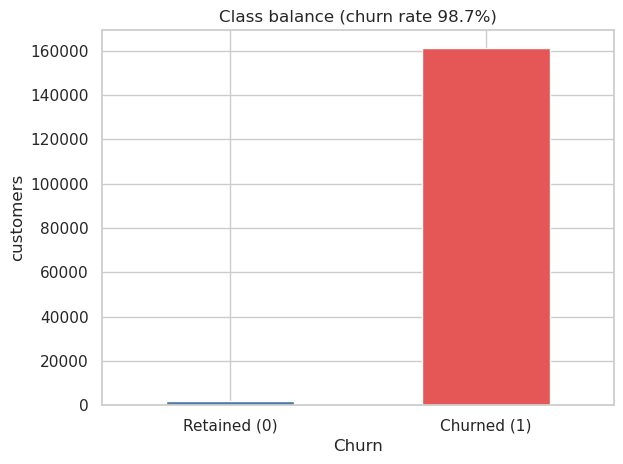

In [6]:
balance = eda[config.TARGET].value_counts().sort_index()
rate = eda[config.TARGET].mean()
print(balance, f"\nchurn rate: {rate:.2%}")

ax = balance.plot(kind="bar", color=["#4c78a8", "#e45756"])
ax.set_xticklabels(["Retained (0)", "Churned (1)"], rotation=0)
ax.set_title(f"Class balance (churn rate {rate:.1%})")
ax.set_ylabel("customers")
savefig("class_balance")

## 4. Numeric features by churn

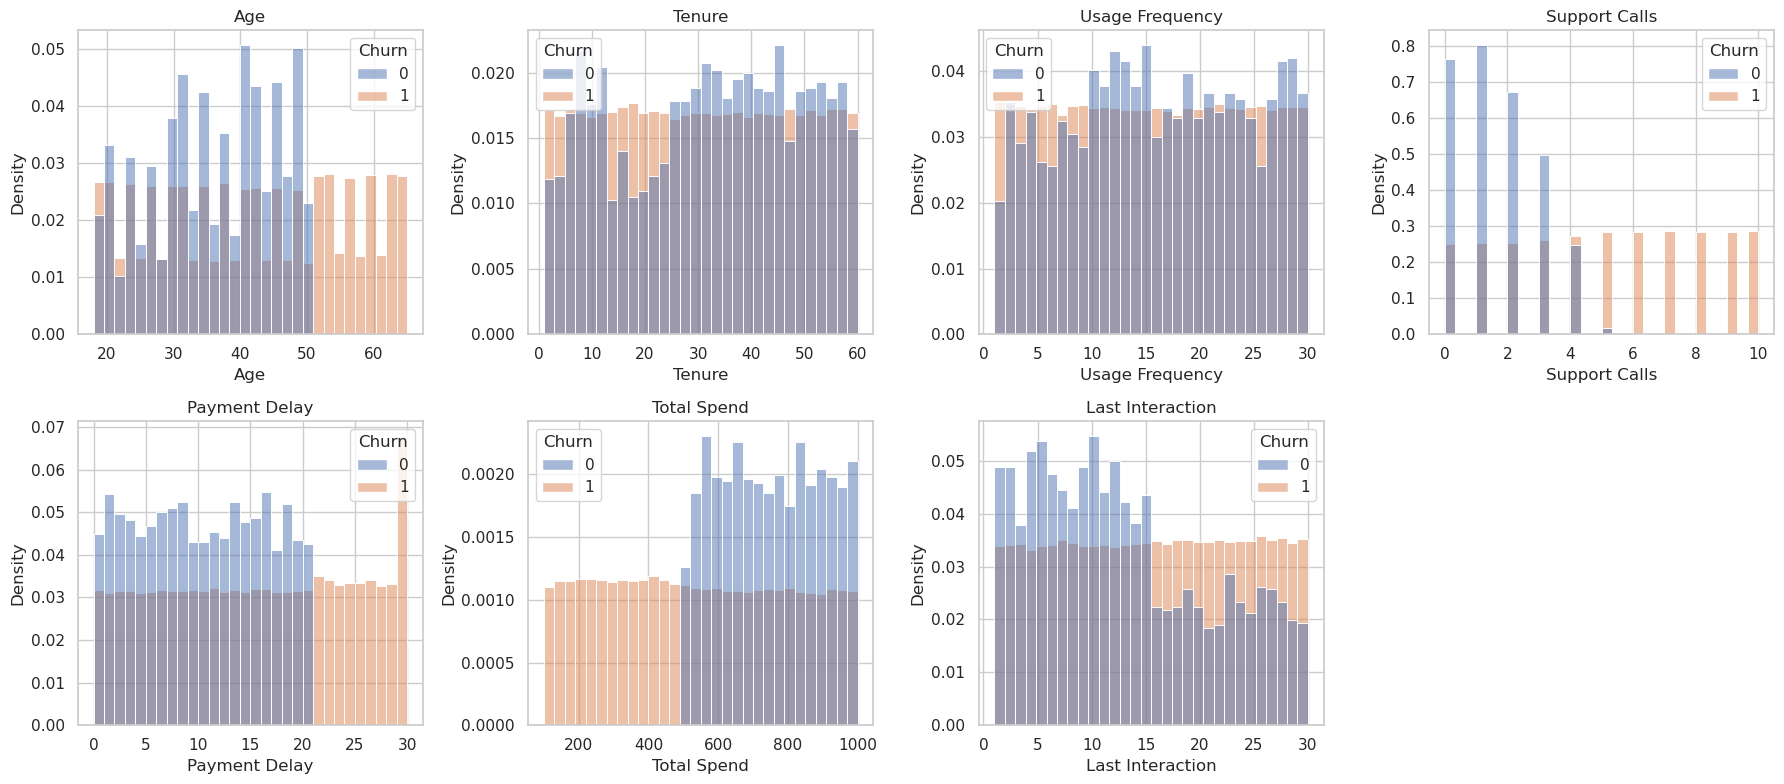

In [7]:
NUMERIC = ["Age", "Tenure", "Usage Frequency", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(data=eda, x=col, hue=config.TARGET, bins=30, stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
savefig("numeric_distributions_by_churn")

## 5. Bivariate analysis: churn rate by category

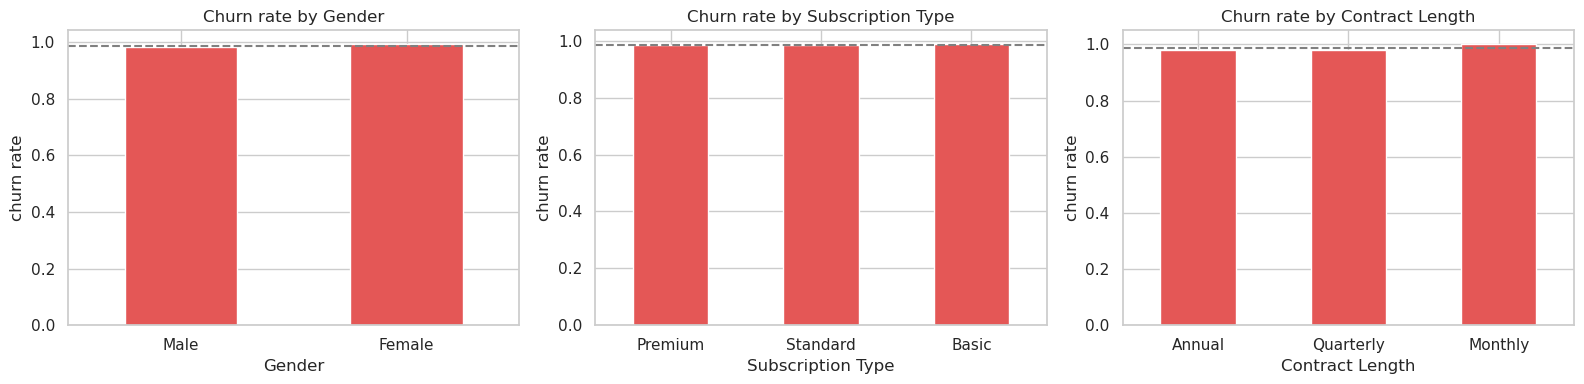

In [8]:
CATEGORICAL = ["Gender", "Subscription Type", "Contract Length"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, CATEGORICAL):
    eda.groupby(col)[config.TARGET].mean().sort_values().plot(kind="bar", ax=ax, color="#e45756")
    ax.axhline(rate, ls="--", c="gray")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("churn rate")
    ax.tick_params(axis="x", rotation=0)
savefig("churn_rate_by_category")

## 6. Bivariate analysis: churn rate by binned numeric features

Binning shows where risk rises (for example, many support calls or long payment delays).

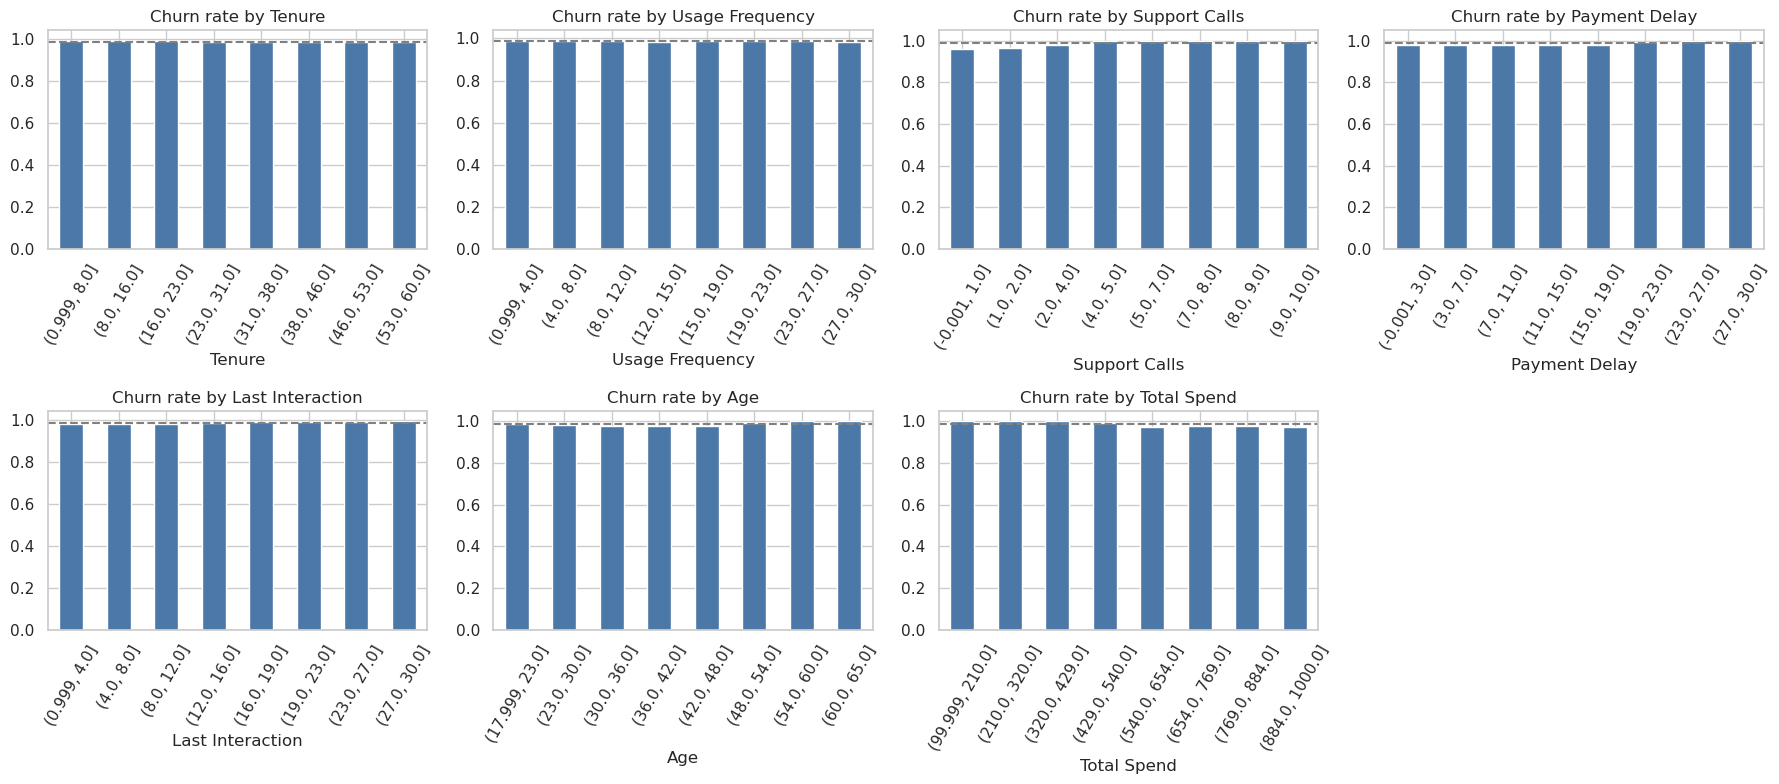

In [9]:
BIN_COLS = ["Tenure", "Usage Frequency", "Support Calls", "Payment Delay", "Last Interaction", "Age", "Total Spend"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), BIN_COLS):
    bins = pd.qcut(eda[col], q=8, duplicates="drop")
    eda.groupby(bins, observed=True)[config.TARGET].mean().plot(kind="bar", ax=ax, color="#4c78a8")
    ax.axhline(rate, ls="--", c="gray")
    ax.set_title(f"Churn rate by {col}")
    ax.tick_params(axis="x", rotation=60)
axes.ravel()[-1].axis("off")
savefig("churn_rate_by_binned_numeric")

## 7. Correlations

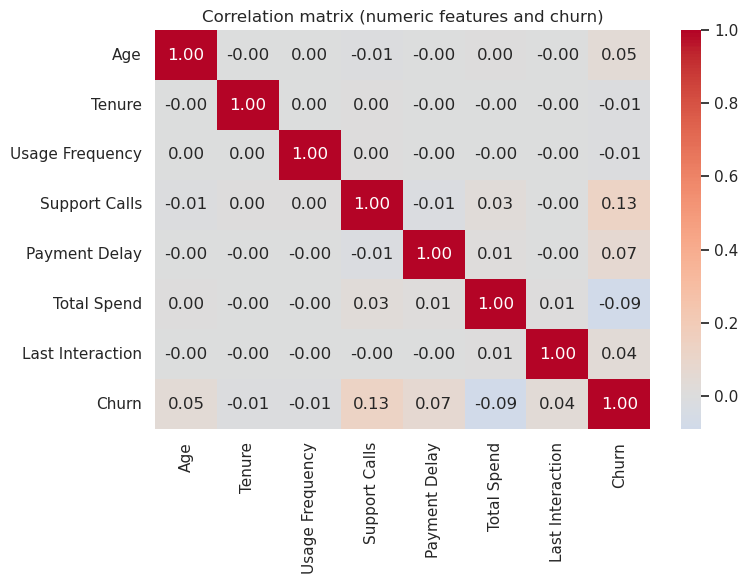

Support Calls       0.129143
Total Spend        -0.090902
Payment Delay       0.067459
Age                 0.047700
Last Interaction    0.036575
Tenure             -0.010258
Usage Frequency    -0.007770
Name: Churn, dtype: float64

In [10]:
corr = eda[NUMERIC + [config.TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features and churn)")
savefig("correlation_heatmap")
corr[config.TARGET].drop(config.TARGET).sort_values(key=abs, ascending=False)

## 8. Do the training and testing files share the same distribution?

The testing file is reserved as unseen "production" data. A Kolmogorov-Smirnov test flags numeric
columns whose distributions differ between the files; categorical share differences are listed too.

In [11]:
rows = []
for col in NUMERIC:
    stat, p = ks_2samp(train[col].dropna(), test[col].dropna())
    rows.append({"feature": col, "ks_stat": round(stat, 4), "p_value": p,
                 "train_mean": round(train[col].mean(), 2), "test_mean": round(test[col].mean(), 2)})
ks = pd.DataFrame(rows).sort_values("ks_stat", ascending=False)
print(ks.to_string(index=False))

if config.TARGET in test.columns:
    print(f"\nchurn rate  train: {train[config.TARGET].mean():.2%} | test: {test[config.TARGET].mean():.2%}")

for col in CATEGORICAL:
    shares = pd.concat([train[col].value_counts(normalize=True).rename("train"),
                        test[col].value_counts(normalize=True).rename("test")], axis=1).round(3)
    print(f"\n{col}\n{shares}")

         feature  ks_stat       p_value  train_mean  test_mean
   Payment Delay   0.1179  0.000000e+00       15.15      17.13
   Support Calls   0.0563 1.046283e-127        5.10       5.40
          Tenure   0.0510 6.291521e-105       30.51      31.99
 Usage Frequency   0.0263  3.188852e-28       15.49      15.08
             Age   0.0093  7.197361e-04       41.68      41.97
     Total Spend   0.0091  8.901323e-04      544.50     541.02
Last Interaction   0.0053  1.546536e-01       15.56      15.50

churn rate  train: 98.69% | test: 47.37%

Gender
        train   test
Gender              
Female  0.506  0.534
Male    0.494  0.466

Subscription Type
                   train   test
Subscription Type              
Standard           0.335  0.334
Premium            0.334  0.333
Basic              0.331  0.333

Contract Length
                 train   test
Contract Length              
Monthly          0.344  0.344
Annual           0.330  0.333
Quarterly        0.327  0.324


In [12]:
%%html

<p><b>Shutting down your kernel for this notebook to release resources.</b></p>
<button class="sm-command-button" data-commandlinker-command="kernelmenu:shutdown" style="display:none;">Shutdown Kernel</button>
        
<script>
try {
    els = document.getElementsByClassName("sm-command-button");
    els[0].click();
}
catch(err) {
    // NoOp
}    
</script>


I0000 00:00:1792393883.374853    3402 chttp2_transport.cc:1182] ipv4:169.255.255.2:41311: Got goaway [2] err=UNAVAILABLE:GOAWAY received; Error code: 2; Debug Text: Cancelling all calls {grpc_status:14, http2_error:2, created_time:"2026-10-19T07:11:23.374844418+00:00"}
*** SIGTERM received at time=1792393885 on cpu 1 ***
PC: @     0x7fb1fad702d2  (unknown)  epoll_wait
[2026-10-19 07:11:25,859 E 3350 3350] logging.cc:474: *** SIGTERM received at time=1792393885 on cpu 1 ***
[2026-10-19 07:11:25,860 E 3350 3350] logging.cc:474: PC: @     0x7fb1fad702d2  (unknown)  epoll_wait
